# Projekt 2: Human Activity Recognition - MLP w PyTorch

**Cel:** sprawdzic, jak gesty perceptron wielowarstwowy zaimplementowany w
PyTorch klasyfikuje aktywnosc czlowieka na podstawie gotowych cech UCI HAR.

Notebook wykorzystuje wektory `561` cech wyliczonych z okien sygnalow
akcelerometru i zyroskopu. Oryginalny test HAR obejmuje inne osoby niz train,
dlatego pozostaje koncowym zbiorem oceny modelu.

## Plan eksperymentu

1. Wczytanie danych HAR i kontrola dostarczonego splitu.
2. Podzial danych treningowych na train/validation po identyfikatorze osoby.
3. Standaryzacja cech dopasowana tylko na wlasciwym train.
4. Trening systematycznej siatki konfiguracji MLP w PyTorch z `DataLoader`,
   `CrossEntropyLoss`, schedulerem i early stopping.
5. Wybor najlepszego checkpointu na walidacji grupowej i ewaluacja baseline
   oraz modelu tuned na oryginalnym tescie HAR.

Model korzysta z `cuda`, gdy PyTorch widzi karte GPU.

In [1]:
from copy import deepcopy
from pathlib import Path
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

HAR_ROOT = (
    Path("human+activity+recognition+using+smartphones")
    / "UCI HAR Dataset"
    / "UCI HAR Dataset"
)
assert HAR_ROOT.exists(), f"Nie znaleziono katalogu HAR: {HAR_ROOT.resolve()}"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Katalog danych: {HAR_ROOT.resolve()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA build: {torch.version.cuda}")
print(f"Urzadzenie treningowe: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Katalog danych: C:\Users\piotr\Desktop\Bartman SI\Projekt 2\human+activity+recognition+using+smartphones\UCI HAR Dataset\UCI HAR Dataset
PyTorch: 2.12.0+cu132
CUDA build: 13.2
Urzadzenie treningowe: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


## 1. Dane HAR

In [2]:
activity_labels = pd.read_csv(
    HAR_ROOT / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"],
)
activity_map = dict(zip(activity_labels["activity_id"], activity_labels["activity"]))

features = pd.read_csv(
    HAR_ROOT / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_index", "feature_name"],
)
feature_columns = [
    f"f{feature_index:03d}_{feature_name}"
    for feature_index, feature_name in zip(features["feature_index"], features["feature_name"])
]

def read_vector(path, column_name):
    return pd.read_csv(path, sep=r"\s+", header=None, names=[column_name])[column_name]

X_train_df = pd.read_csv(HAR_ROOT / "train" / "X_train.txt", sep=r"\s+", header=None, names=feature_columns)
X_test_df = pd.read_csv(HAR_ROOT / "test" / "X_test.txt", sep=r"\s+", header=None, names=feature_columns)
y_train_ids = read_vector(HAR_ROOT / "train" / "y_train.txt", "activity_id").astype(int)
y_test_ids = read_vector(HAR_ROOT / "test" / "y_test.txt", "activity_id").astype(int)
subject_train = read_vector(HAR_ROOT / "train" / "subject_train.txt", "subject_id").astype(int)
subject_test = read_vector(HAR_ROOT / "test" / "subject_test.txt", "subject_id").astype(int)

# CrossEntropyLoss oczekuje klas 0..C-1.
y_train_zero = y_train_ids.to_numpy(dtype=np.int64) - 1
y_test_zero = y_test_ids.to_numpy(dtype=np.int64) - 1

summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "windows": [len(X_train_df), len(X_test_df)],
        "features": [X_train_df.shape[1], X_test_df.shape[1]],
        "subjects": [subject_train.nunique(), subject_test.nunique()],
        "missing_values": [int(X_train_df.isna().sum().sum()), int(X_test_df.isna().sum().sum())],
        "min_feature_value": [X_train_df.min().min(), X_test_df.min().min()],
        "max_feature_value": [X_train_df.max().max(), X_test_df.max().max()],
    }
)

display(summary.round(4))
print(f"Aktywnosci: {activity_map}")
print(f"Osoby train: {sorted(subject_train.unique())}")
print(f"Osoby test:  {sorted(subject_test.unique())}")
print(f"Czesc wspolna osob: {sorted(set(subject_train.unique()) & set(subject_test.unique()))}")
X_train_df.iloc[:5, :8]

,split,windows,features,subjects,missing_values,min_feature_value,max_feature_value
0,train,7352,561,21,0,-1.0,1.0
1,test,2947,561,9,0,-1.0,1.0


Aktywnosci: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}
Osoby train: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Osoby test:  [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Czesc wspolna osob: []


,f001_tBodyAcc-mean()-X,f002_tBodyAcc-mean()-Y,f003_tBodyAcc-mean()-Z,f004_tBodyAcc-std()-X,f005_tBodyAcc-std()-Y,f006_tBodyAcc-std()-Z,f007_tBodyAcc-mad()-X,f008_tBodyAcc-mad()-Y
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672


,split,activity_id,activity,windows,share_percent
0,train,1,WALKING,1226,16.7
1,train,2,WALKING_UPSTAIRS,1073,14.6
2,train,3,WALKING_DOWNSTAIRS,986,13.4
3,train,4,SITTING,1286,17.5
4,train,5,STANDING,1374,18.7
5,train,6,LAYING,1407,19.1
6,test,1,WALKING,496,16.8
7,test,2,WALKING_UPSTAIRS,471,16.0
8,test,3,WALKING_DOWNSTAIRS,420,14.3
9,test,4,SITTING,491,16.7


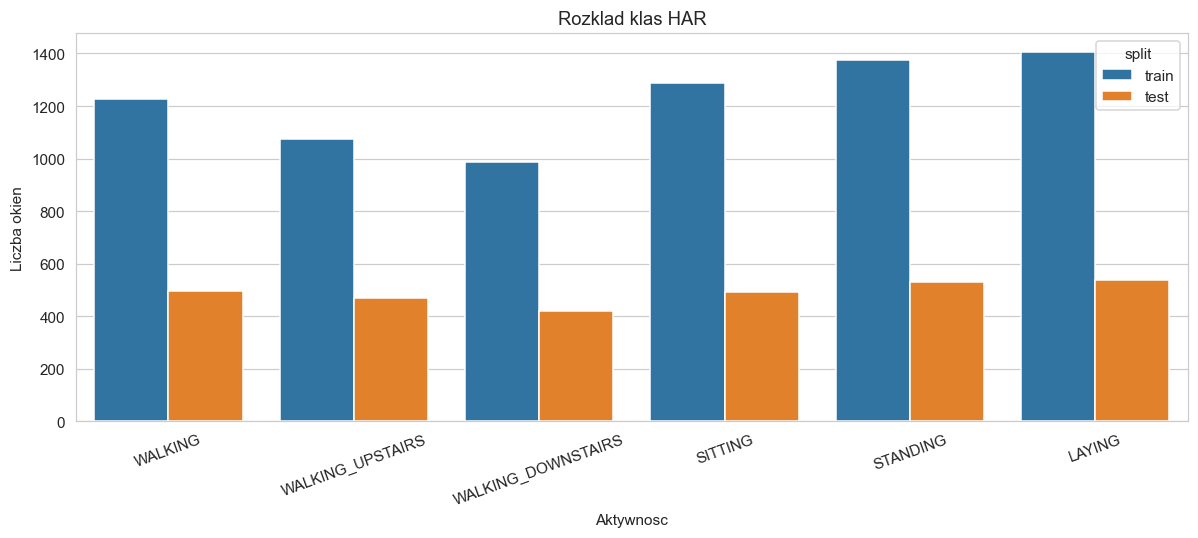

In [3]:
def class_count_table(labels, split_name):
    counts = labels.value_counts().sort_index()
    return pd.DataFrame(
        {
            "split": split_name,
            "activity_id": counts.index,
            "activity": [activity_map[class_id] for class_id in counts.index],
            "windows": counts.values,
            "share_percent": (counts.values / counts.values.sum() * 100).round(1),
        }
    )

class_counts = pd.concat(
    [class_count_table(y_train_ids, "train"), class_count_table(y_test_ids, "test")],
    ignore_index=True,
)
display(class_counts)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=class_counts, x="activity", y="windows", hue="split", ax=ax)
ax.set_title("Rozklad klas HAR")
ax.set_xlabel("Aktywnosc")
ax.set_ylabel("Liczba okien")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 2. Walidacja po osobach i preprocessing

Oryginalny test zostaje nietkniety. Z train wydzielamy jeden fold walidacyjny
przez `StratifiedGroupKFold`, aby okna tej samej osoby nie trafily jednoczesnie
do czesci uczacej i walidacyjnej.

In [4]:
splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
fit_indices, val_indices = next(
    splitter.split(X_train_df, y_train_zero, groups=subject_train.to_numpy())
)

X_fit_df = X_train_df.iloc[fit_indices]
X_val_df = X_train_df.iloc[val_indices]
y_fit = y_train_zero[fit_indices]
y_val = y_train_zero[val_indices]
fit_subjects = subject_train.iloc[fit_indices]
val_subjects = subject_train.iloc[val_indices]

scaler = StandardScaler()
X_fit = scaler.fit_transform(X_fit_df).astype(np.float32)
X_val = scaler.transform(X_val_df).astype(np.float32)

print(f"Fit: {X_fit.shape}, validation: {X_val.shape}")
print(f"Osoby fit: {sorted(fit_subjects.unique())}")
print(f"Osoby validation: {sorted(val_subjects.unique())}")
print(f"Czesc wspolna osob fit/validation: {sorted(set(fit_subjects) & set(val_subjects))}")
print("Rozklad validation:")
print(pd.Series(y_val + 1).value_counts().sort_index().rename(index=activity_map))

Fit: (5563, 561), validation: (1789, 561)
Osoby fit: [np.int64(1), np.int64(3), np.int64(5), np.int64(7), np.int64(8), np.int64(14), np.int64(15), np.int64(16), np.int64(19), np.int64(22), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Osoby validation: [np.int64(6), np.int64(11), np.int64(17), np.int64(21), np.int64(23)]
Czesc wspolna osob fit/validation: []
Rozklad validation:
WALKING               288
WALKING_UPSTAIRS      251
WALKING_DOWNSTAIRS    239
SITTING               325
STANDING              339
LAYING                347
Name: count, dtype: int64


In [5]:
def make_loader(X, y, batch_size, shuffle):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long),
    )
    generator = torch.Generator().manual_seed(RANDOM_STATE)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)

fit_loader = make_loader(X_fit, y_fit, batch_size=256, shuffle=True)
val_loader = make_loader(X_val, y_val, batch_size=512, shuffle=False)

print(f"Batchy fit: {len(fit_loader)}, batchy validation: {len(val_loader)}")

Batchy fit: 22, batchy validation: 4


## 3. Architektura i funkcje treningowe PyTorch

In [6]:
class HarMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout, num_classes):
        super().__init__()
        layers = []
        previous_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend(
                [
                    nn.Linear(previous_dim, hidden_dim),
                    nn.BatchNorm1d(hidden_dim),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                ]
            )
            previous_dim = hidden_dim
        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def collect_predictions(model, loader):
    model.eval()
    all_true = []
    all_pred = []
    with torch.no_grad():
        for features_batch, labels_batch in loader:
            features_batch = features_batch.to(DEVICE)
            logits = model(features_batch)
            predictions = logits.argmax(dim=1).cpu().numpy()
            all_true.append(labels_batch.numpy())
            all_pred.append(predictions)
    return np.concatenate(all_true), np.concatenate(all_pred)


def evaluate_loader(model, loader, loss_function):
    model.eval()
    total_loss = 0.0
    total_examples = 0
    with torch.no_grad():
        for features_batch, labels_batch in loader:
            features_batch = features_batch.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)
            logits = model(features_batch)
            loss = loss_function(logits, labels_batch)
            total_loss += loss.item() * len(labels_batch)
            total_examples += len(labels_batch)
    y_true, y_pred = collect_predictions(model, loader)
    return {
        "loss": total_loss / total_examples,
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }


def train_with_early_stopping(config, train_loader, validation_loader, input_dim, num_classes):
    model = HarMLP(
        input_dim=input_dim,
        hidden_dims=config["hidden_dims"],
        dropout=config["dropout"],
        num_classes=num_classes,
    ).to(DEVICE)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=config["scheduler_patience"],
        min_lr=1e-5,
    )

    history = []
    best_state = None
    best_val_f1 = -np.inf
    wait = 0

    for epoch in range(1, config["max_epochs"] + 1):
        model.train()
        train_loss_total = 0.0
        train_examples = 0

        for features_batch, labels_batch in train_loader:
            features_batch = features_batch.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features_batch)
            loss = loss_function(logits, labels_batch)
            loss.backward()
            optimizer.step()
            train_loss_total += loss.item() * len(labels_batch)
            train_examples += len(labels_batch)

        train_true, train_pred = collect_predictions(model, train_loader)
        validation_metrics = evaluate_loader(model, validation_loader, loss_function)
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss_total / train_examples,
                "train_f1_macro": f1_score(train_true, train_pred, average="macro"),
                "val_loss": validation_metrics["loss"],
                "val_accuracy": validation_metrics["accuracy"],
                "val_f1_macro": validation_metrics["f1_macro"],
                "learning_rate": optimizer.param_groups[0]["lr"],
            }
        )
        scheduler.step(validation_metrics["f1_macro"])

        if validation_metrics["f1_macro"] > best_val_f1 + config["min_delta"]:
            best_val_f1 = validation_metrics["f1_macro"]
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= config["patience"]:
                break

    model.load_state_dict(best_state)
    history_df = pd.DataFrame(history)
    return model, history_df, best_val_f1


print(HarMLP(input_dim=X_fit.shape[1], hidden_dims=(128, 64), dropout=0.2, num_classes=6))

HarMLP(
  (network): Sequential(
    (0): Linear(in_features=561, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=6, bias=True)
  )
)


## 4. Porownanie kilku konfiguracji MLP

In [7]:
architecture_grid = {
    "MLP64": (64,),
    "MLP128": (128,),
    "MLP128_64": (128, 64),
    "MLP256_128": (256, 128),
}
dropout_grid = [0.10, 0.20, 0.30]
learning_rate_grid = [5e-4, 1e-3]
baseline_signature = {
    "hidden_dims": (128, 64),
    "dropout": 0.20,
    "learning_rate": 1e-3,
}

candidate_configs = []
for architecture_name, hidden_dims in architecture_grid.items():
    for dropout in dropout_grid:
        for learning_rate in learning_rate_grid:
            is_baseline = (
                hidden_dims == baseline_signature["hidden_dims"]
                and dropout == baseline_signature["dropout"]
                and learning_rate == baseline_signature["learning_rate"]
            )
            candidate_configs.append(
                {
                    "name": f"{architecture_name}_d{int(dropout * 10):02d}_lr{learning_rate:.0e}",
                    "hidden_dims": hidden_dims,
                    "dropout": dropout,
                    "learning_rate": learning_rate,
                    "weight_decay": 1e-4,
                    "max_epochs": 160,
                    "patience": 16,
                    "scheduler_patience": 5,
                    "min_delta": 1e-4,
                    "is_baseline": is_baseline,
                }
            )

candidate_models = {}
candidate_histories = {}
candidate_rows = []

for config in candidate_configs:
    print(f"Trening {config['name']} na {DEVICE}...")
    model, history, best_val_f1 = train_with_early_stopping(
        config=config,
        train_loader=fit_loader,
        validation_loader=val_loader,
        input_dim=X_fit.shape[1],
        num_classes=len(activity_map),
    )
    candidate_models[config["name"]] = model
    candidate_histories[config["name"]] = history
    candidate_rows.append(
        {
            "config": config["name"],
            "hidden_dims": config["hidden_dims"],
            "dropout": config["dropout"],
            "learning_rate": config["learning_rate"],
            "weight_decay": config["weight_decay"],
            "role": "baseline" if config["is_baseline"] else "grid",
            "is_baseline": config["is_baseline"],
            "epochs_run": int(history["epoch"].iloc[-1]),
            "best_val_f1_macro": best_val_f1,
        }
    )

candidate_results = pd.DataFrame(candidate_rows).sort_values("best_val_f1_macro", ascending=False)
baseline_config_name = candidate_results.loc[candidate_results["is_baseline"], "config"].iloc[0]
tuned_config_name = candidate_results.iloc[0]["config"]

print(f"Liczba sprawdzonych konfiguracji: {len(candidate_configs)}")
print(f"Baseline: {baseline_config_name}")
print(f"Najlepszy wariant tuned: {tuned_config_name}")
candidate_results.drop(columns="is_baseline").head(12).round(4)

Trening MLP64_d01_lr5e-04 na cuda...


Trening MLP64_d01_lr1e-03 na cuda...


Trening MLP64_d02_lr5e-04 na cuda...


Trening MLP64_d02_lr1e-03 na cuda...


Trening MLP64_d03_lr5e-04 na cuda...


...

Trening MLP256_128_d02_lr1e-03 na cuda...


Trening MLP256_128_d03_lr5e-04 na cuda...


Trening MLP256_128_d03_lr1e-03 na cuda...


Liczba sprawdzonych konfiguracji: 24
Baseline: MLP128_64_d02_lr1e-03
Najlepszy wariant tuned: MLP128_64_d03_lr1e-03


,config,hidden_dims,dropout,learning_rate,weight_decay,role,epochs_run,best_val_f1_macro
17,MLP128_64_d03_lr1e-03,"(128, 64)",0.3,0.0010,0.0001,grid,42,0.9662
20,MLP256_128_d02_lr5e-04,"(256, 128)",0.2,0.0005,0.0001,grid,58,0.9627
13,MLP128_64_d01_lr1e-03,"(128, 64)",0.1,0.0010,0.0001,grid,41,0.9625
16,MLP128_64_d03_lr5e-04,"(128, 64)",0.3,0.0005,0.0001,grid,49,0.9615
11,MLP128_d03_lr1e-03,"(128,)",0.3,0.0010,0.0001,grid,38,0.9602
9,MLP128_d02_lr1e-03,"(128,)",0.2,0.0010,0.0001,grid,37,0.9599
21,MLP256_128_d02_lr1e-03,"(256, 128)",0.2,0.0010,0.0001,grid,37,0.9591
18,MLP256_128_d01_lr5e-04,"(256, 128)",0.1,0.0005,0.0001,grid,33,0.9584
19,MLP256_128_d01_lr1e-03,"(256, 128)",0.1,0.0010,0.0001,grid,35,0.9578
23,MLP256_128_d03_lr1e-03,"(256, 128)",0.3,0.0010,0.0001,grid,29,0.9574


,family,config,dropout,learning_rate,epochs_run,best_val_f1_macro
17,128,MLP128_64_d03_lr1e-03,0.3,0.0010,42,0.9662
20,256,MLP256_128_d02_lr5e-04,0.2,0.0005,58,0.9627
1,64,MLP64_d01_lr1e-03,0.1,0.0010,48,0.9560


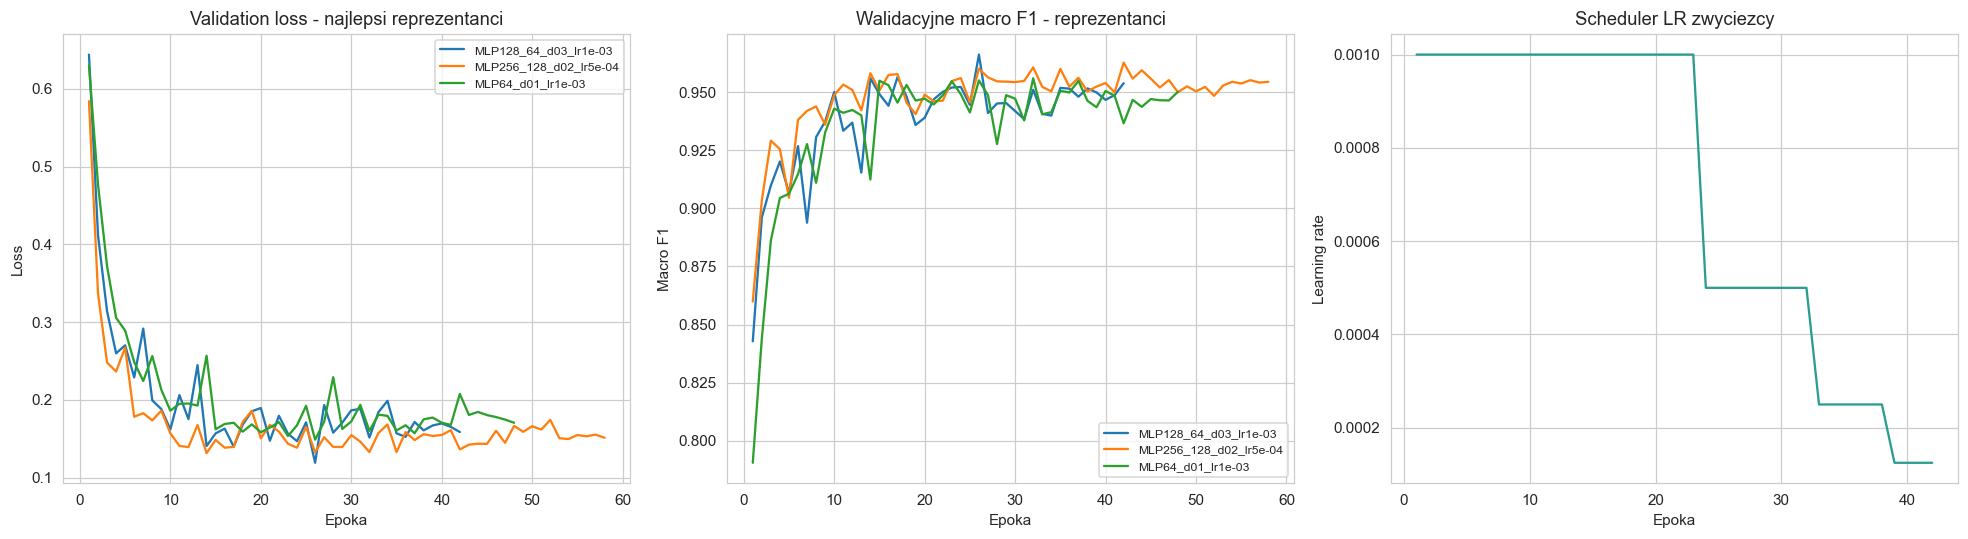

In [8]:
candidate_results["family"] = np.select(
    [
        candidate_results["config"].str.startswith("MLP64"),
        candidate_results["config"].str.startswith("MLP256"),
        candidate_results["config"].str.startswith("MLP128"),
    ],
    ["64", "256", "128"],
    default="other",
)
representatives = (
    candidate_results.sort_values("best_val_f1_macro", ascending=False)
    .groupby("family", sort=False)
    .head(1)
    .sort_values("best_val_f1_macro", ascending=False)
)
display(
    representatives[
        ["family", "config", "dropout", "learning_rate", "epochs_run", "best_val_f1_macro"]
    ].round(4)
)

palette = dict(zip(representatives["config"], sns.color_palette("tab10", len(representatives))))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for row in representatives.itertuples():
    history = candidate_histories[row.config]
    color = palette[row.config]
    label = row.config
    axes[0].plot(history["epoch"], history["val_loss"], color=color, label=label)
    axes[1].plot(history["epoch"], history["val_f1_macro"], color=color, label=row.config)

axes[0].set_title("Validation loss - najlepsi reprezentanci")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
axes[1].set_title("Walidacyjne macro F1 - reprezentanci")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Macro F1")
axes[1].legend(fontsize=8)
best_history_for_scheduler = candidate_histories[tuned_config_name]
axes[2].plot(
    best_history_for_scheduler["epoch"],
    best_history_for_scheduler["learning_rate"],
    color="#2a9d8f",
)
axes[2].set_title("Scheduler LR zwyciezcy")
axes[2].set_xlabel("Epoka")
axes[2].set_ylabel("Learning rate")
plt.tight_layout()
plt.show()

## 5. Wybor checkpointow do testu

Do finalnej ewaluacji wykorzystujemy checkpointy zapisane przez early stopping:
staly baseline oraz najlepszy wariant tuned z siatki konfiguracji. Oryginalny
test HAR nie uczestniczy ani w doborze hiperparametrow, ani w zatrzymywaniu
treningu.

In [9]:
baseline_model = candidate_models[baseline_config_name]
tuned_model = candidate_models[tuned_config_name]
baseline_history = candidate_histories[baseline_config_name]
tuned_history = candidate_histories[tuned_config_name]

X_test_scaled = scaler.transform(X_test_df).astype(np.float32)
test_loader = make_loader(X_test_scaled, y_test_zero, batch_size=512, shuffle=False)

baseline_val_f1 = candidate_results.loc[
    candidate_results["config"] == baseline_config_name, "best_val_f1_macro"
].iloc[0]
tuned_val_f1 = candidate_results.loc[
    candidate_results["config"] == tuned_config_name, "best_val_f1_macro"
].iloc[0]

print(f"Baseline checkpoint: {baseline_config_name}, val macro F1 = {baseline_val_f1:.4f}")
print(f"Tuned checkpoint:    {tuned_config_name}, val macro F1 = {tuned_val_f1:.4f}")
print(f"Test loader: {len(test_loader.dataset)} okien, skalowanie z fit folda")

Baseline checkpoint: MLP128_64_d02_lr1e-03, val macro F1 = 0.9552
Tuned checkpoint:    MLP128_64_d03_lr1e-03, val macro F1 = 0.9662
Test loader: 2947 okien, skalowanie z fit folda


## 6. Ewaluacja na oryginalnym tescie HAR

In [10]:
baseline_true_zero, baseline_pred_zero = collect_predictions(baseline_model, test_loader)
tuned_true_zero, tuned_pred_zero = collect_predictions(tuned_model, test_loader)
baseline_true_ids = baseline_true_zero + 1
baseline_pred_ids = baseline_pred_zero + 1
tuned_true_ids = tuned_true_zero + 1
tuned_pred_ids = tuned_pred_zero + 1

def metric_row(model_name, y_true, y_pred):
    per_class = f1_score(y_true, y_pred, labels=sorted(activity_map), average=None)
    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro"),
        "Recall_macro": recall_score(y_true, y_pred, average="macro"),
        "F1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    row.update(
        {
            f"F1_{activity_map[class_id]}": score
            for class_id, score in zip(sorted(activity_map), per_class)
        }
    )
    return row

pytorch_test_metrics = pd.DataFrame(
    [
        metric_row(f"PyTorch baseline - {baseline_config_name}", baseline_true_ids, baseline_pred_ids),
        metric_row(f"PyTorch tuned - {tuned_config_name}", tuned_true_ids, tuned_pred_ids),
    ]
).set_index("Model")

# Referencja z osobnego notebooka sklearn HAR na tym samym oryginalnym tescie.
sklearn_reference = pd.DataFrame(
    [
        {
            "Model": "sklearn tuned MLPClassifier",
            "Accuracy": 0.9433,
            "Precision_macro": 0.9492,
            "Recall_macro": 0.9418,
            "F1_macro": 0.9434,
        }
    ]
).set_index("Model")
summary_columns = ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]
method_comparison = pd.concat([sklearn_reference, pytorch_test_metrics[summary_columns]])

display(method_comparison.round(4).sort_values("F1_macro", ascending=False))
pytorch_test_metrics.round(4)

,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,
PyTorch tuned - MLP128_64_d03_lr1e-03,0.9606,0.9636,0.9606,0.9614
PyTorch baseline - MLP128_64_d02_lr1e-03,0.9586,0.9608,0.9582,0.9591
sklearn tuned MLPClassifier,0.9433,0.9492,0.9418,0.9434


,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_WALKING,F1_WALKING_UPSTAIRS,F1_WALKING_DOWNSTAIRS,F1_SITTING,F1_STANDING,F1_LAYING
Model,,,,,,,,,,
PyTorch baseline - MLP128_64_d02_lr1e-03,0.9586,0.9608,0.9582,0.9591,0.9733,0.9722,0.9745,0.9181,0.9236,0.9925
PyTorch tuned - MLP128_64_d03_lr1e-03,0.9606,0.9636,0.9606,0.9614,0.9859,0.9800,0.9794,0.9151,0.9184,0.9897


Classification report - PyTorch baseline
                    precision    recall  f1-score   support

           WALKING       0.95      0.99      0.97       496
  WALKING_UPSTAIRS       0.98      0.97      0.97       471
WALKING_DOWNSTAIRS       0.99      0.96      0.97       420
           SITTING       0.95      0.89      0.92       491
          STANDING       0.89      0.95      0.92       532
            LAYING       1.00      0.99      0.99       537

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947

Classification report - PyTorch tuned
                    precision    recall  f1-score   support

           WALKING       0.98      0.99      0.99       496
  WALKING_UPSTAIRS       0.97      0.99      0.98       471
WALKING_DOWNSTAIRS       1.00      0.96      0.98       420
           SITTING       0.96      0.88      0.92       491
          STANDIN

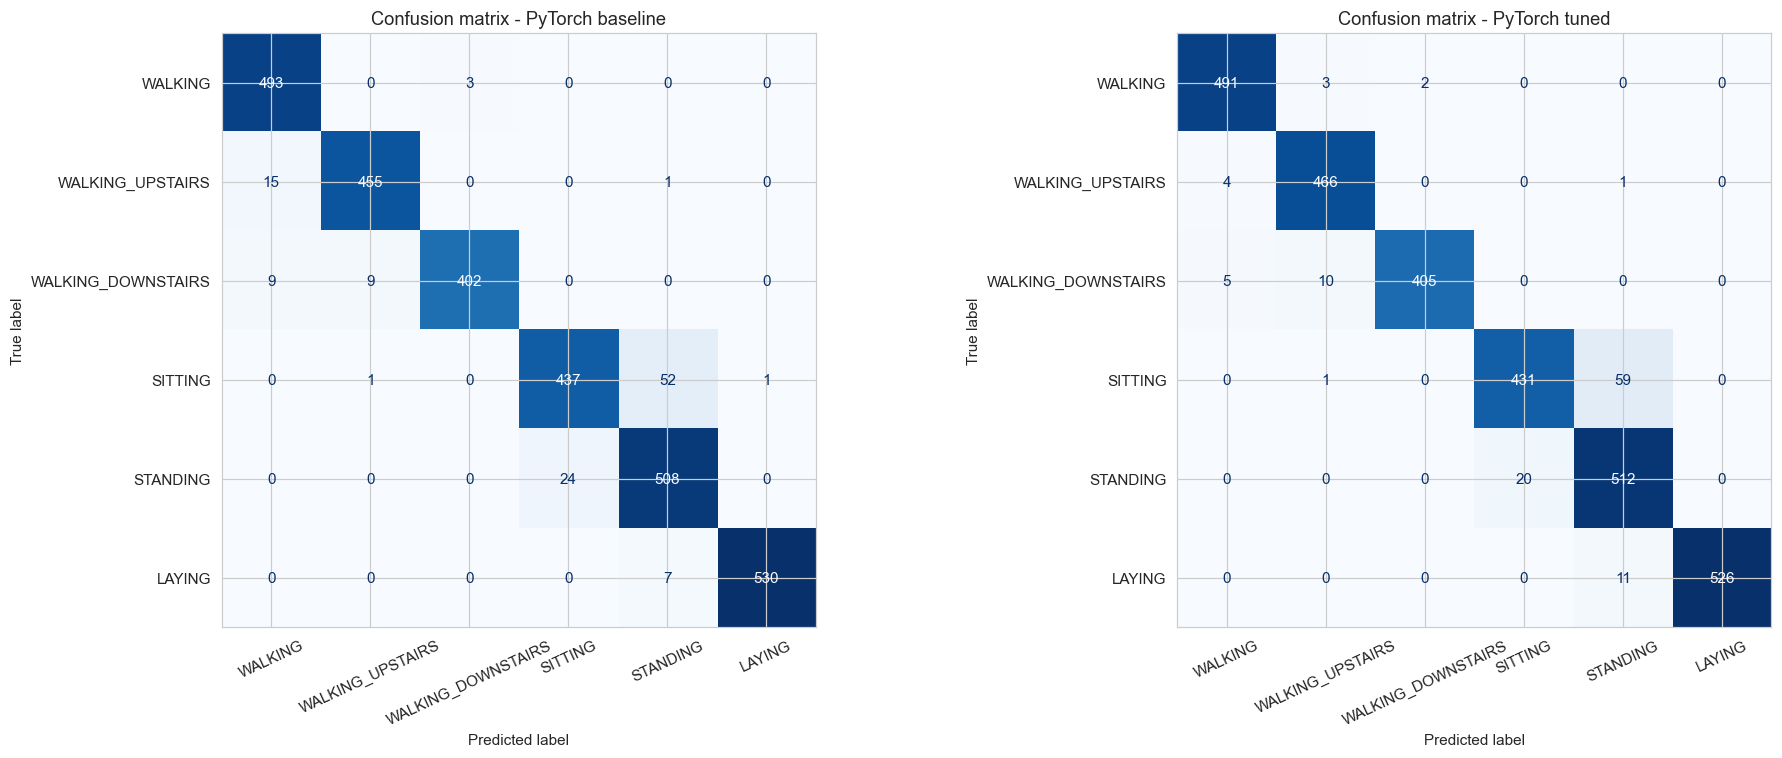

In [11]:
target_names = [activity_map[class_id] for class_id in sorted(activity_map)]
print("Classification report - PyTorch baseline")
print(classification_report(baseline_true_ids, baseline_pred_ids, target_names=target_names))
print("Classification report - PyTorch tuned")
print(classification_report(tuned_true_ids, tuned_pred_ids, target_names=target_names))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, y_true, y_pred, title in [
    (axes[0], baseline_true_ids, baseline_pred_ids, "PyTorch baseline"),
    (axes[1], tuned_true_ids, tuned_pred_ids, "PyTorch tuned"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=sorted(activity_map),
        display_labels=target_names,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=25,
        ax=ax,
    )
    ax.set_title(f"Confusion matrix - {title}")
plt.tight_layout()
plt.show()

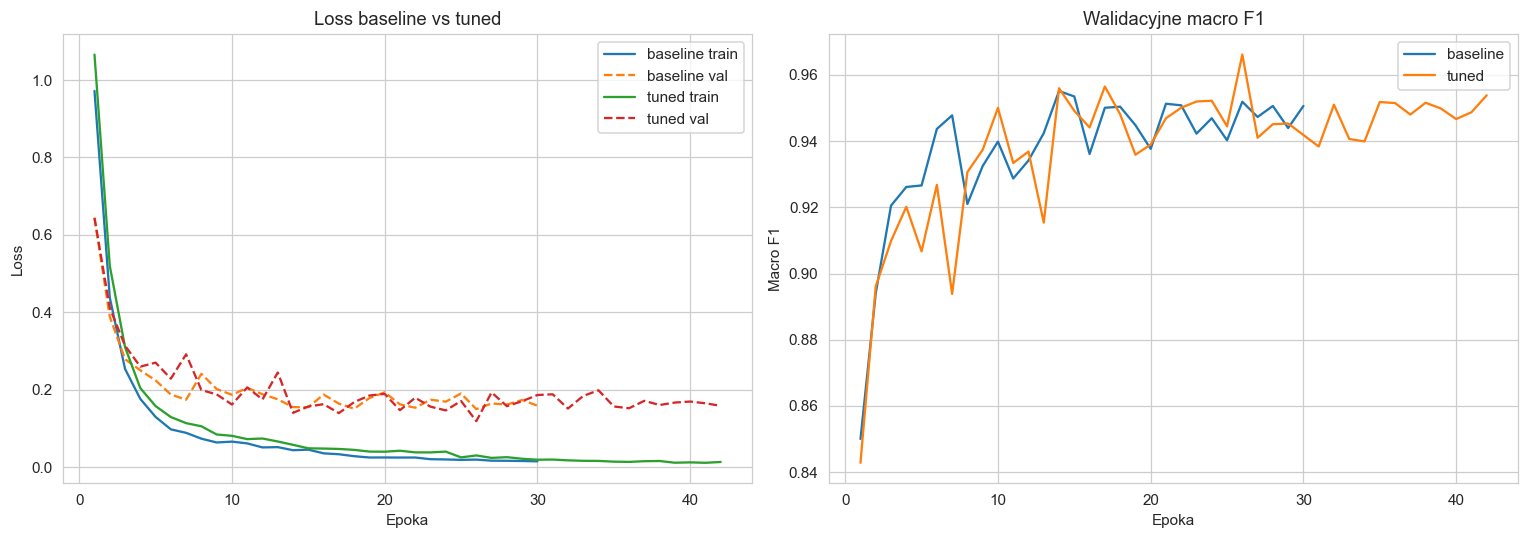

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, history in [
    ("baseline", baseline_history),
    ("tuned", tuned_history),
]:
    axes[0].plot(history["epoch"], history["train_loss"], label=f"{label} train")
    axes[0].plot(history["epoch"], history["val_loss"], linestyle="--", label=f"{label} val")
    axes[1].plot(history["epoch"], history["val_f1_macro"], label=label)

axes[0].set_title("Loss baseline vs tuned")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].set_title("Walidacyjne macro F1")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Wnioski

Eksperyment potwierdzil, ze UCI HAR jest dobrym zbiorem do projektu sieci
neuronowej. MLP pracowalo na `561` cechach opisujacych okna sygnalow z
akcelerometru i zyroskopu, a zadanie obejmowalo `6` klas aktywnosci. Zachowano
oryginalny test HAR z innymi osobami niz w train. Dodatkowa walidacja architektur
zostala wydzielona z train przez `StratifiedGroupKFold` po identyfikatorze osoby,
co ogranicza ryzyko zawyzenia wynikow przez walidacje na oknach tej samej osoby.

### Wynik i dobor architektury

PyTorch poprawnie wykorzystal GPU (`cuda`, `NVIDIA GeForce RTX 5070 Ti`).
Zamiast kilku recznie ustawionych wariantow sprawdzono systematyczna siatke
`24` konfiguracji laczaca architektury MLP, dropout oraz learning rate. Kazdy
trening korzystal z `ReduceLROnPlateau` i early stopping na walidacji po osobach.

Najlepszym checkpointem zostal `MLP128_64_d03_lr1e-03`: dwuwarstwowe MLP z
dropoutem `0.30` i learning rate `1e-03`. Na walidacji uzyskal
`macro F1 = 0.9662`, a na oryginalnym tescie HAR `accuracy = 0.9606` oraz
`macro F1 = 0.9614`. Staly baseline `MLP128_64_d02_lr1e-03` osiagnal
odpowiednio walidacyjne `macro F1 = 0.9552` i testowe `macro F1 = 0.9591`.
Tuning poprawil wiec wynik, ale na tescie roznica wzgledem baseline jest mala
(`+0.0023` macro F1), mimo wyrazniejszej przewagi na walidacji (`+0.0110`).
Oznacza to, ze najlepsze konfiguracje sa do siebie jakosciowo zblizone i nie
nalezy przeceniac pojedynczej roznicy po siatce hiperparametrow.

Wyniki siatki wskazuja tez, ze zwiekszanie modelu nie bylo konieczne. Najlepszy
reprezentant rodziny `256` osiagnal walidacyjne `macro F1 = 0.9627`, czyli byl
blisko zwyciezcy, ale nie przebil umiarkowanej architektury `128_64`. Do testu
uzyto checkpointow wybranych przez walidacje z early stopping, bez refitu ze
sztywno narzucona liczba epok.

### Interpretacja jakosci

Najlepsze MLP bardzo dobrze rozpoznawalo aktywnosci dynamiczne: `F1` wynioslo
`0.99` dla `WALKING` oraz okolo `0.98` dla obu wariantow chodzenia po schodach.
Bardzo wysoki wynik uzyskano tez dla `LAYING` (`F1 = 0.99`). Najtrudniejsze
pozostaly aktywnosci statyczne `SITTING` i `STANDING`, obie z wynikiem `F1`
okolo `0.92`. Raport pokazuje nizszy recall dla `SITTING` (`0.88`) oraz nizsza
precision dla `STANDING` (`0.88`), co pasuje do pomylek miedzy podobnymi
pozycjami statycznymi widocznych w macierzy pomylek.

### Porownanie z notebookiem sklearn

Wersja PyTorch uzyskala lepszy wynik testowy niz wczesniejszy notebook oparty
na `MLPClassifier` ze sklearn (`macro F1 = 0.9614` wobec `0.9434`, roznica
`+0.0180`). Porownanie odbywa sie na tym samym tescie HAR, a notebook zawiera
tabele metryk, raporty klas oraz macierze pomylek baseline vs tuned. PyTorch
pokazuje tez pelniejszy przebieg pracy z siecia neuronowa: jawna architekture
`nn.Module`, `DataLoader`, funkcje straty, optimizer, scheduler, epoki,
early stopping i trening na GPU. Dlatego ten wariant nadaje sie lepiej na
finalna wersje projektu MLP.